# Primera parte
1. Lea el caso aplicativo “How To Use The 7 Step BSPF: A Customer Churn Example”
2. Explique con sus palabras de forma breve en qué consisten cada uno de los siete pasos planteados para crear un “Business Science Problem Framework (BSPF)” en este caso.
3. Comente si es aplicable a su entorno laboral y por qué. 

## Entrega 
## Los 7 pasos del Business Science Problem Framework (BSPF) en un tono técnico y formal

El artículo "How To Use The 7 Step BSPF: A Customer Churn Example" ([https://www.business-science.io/business/2018/06/19/business-science-problem-framework.html](https://www.business-science.io/business/2018/06/19/business-science-problem-framework.html)) presenta un marco metodológico de siete pasos para la definición y resolución de problemas empresariales mediante la aplicación de la ciencia de datos. Estos pasos son los siguientes:

**1. Definición del problema:** En esta etapa inicial se establece el problema empresarial de manera clara y concisa. Esto implica la identificación de los objetivos específicos a alcanzar y la comprensión del contexto en el que se enmarca el problema.

**2. Formulación de una hipótesis:** Se plantea una hipótesis que explique las causas subyacentes del problema. Esta hipótesis debe cumplir con los criterios de especificidad, mensurabilidad, alcanzabilidad, relevancia y temporalidad (SMART).

**3. Recopilación de datos:** Se procede a la recolección de los datos necesarios para evaluar la hipótesis formulada. Estos datos pueden provenir de diversas fuentes, tales como bases de datos internas, encuestas o experimentos diseñados específicamente.

**4. Exploración de datos:** Se realiza un análisis exploratorio de los datos recopilados para comprender su estructura, distribución y patrones relevantes. Esta etapa puede ayudar a identificar variables significativas y posibles sesgos en la información.

**5. Modelado:** Se construye un modelo estadístico que explique la relación entre las variables y el problema empresarial planteado. El tipo de modelo utilizado puede ser un modelo de regresión, un modelo de clasificación o cualquier otro modelo estadístico adecuado.

**6. Evaluación del modelo:** Se evalúa el rendimiento del modelo construido utilizando métricas apropiadas. Estas métricas deben estar alineadas con los objetivos específicos del problema empresarial.

**7. Implementación de la solución:** Si el modelo demuestra un rendimiento satisfactorio, se procede a la implementación de la solución en el contexto empresarial. Esto puede implicar cambios en los procesos, productos o servicios ofrecidos.

## Aplicabilidad en el entorno laboral

La aplicabilidad del BSPF en un entorno laboral específico dependerá de diversos factores, tales como la disponibilidad de datos, la cultura organizacional y las habilidades del equipo de ciencia de datos. En general, el BSPF se presenta como una herramienta valiosa para aquellas empresas que buscan utilizar la ciencia de datos para resolver problemas empresariales de manera efectiva. El marco metodológico proporciona una guía clara y estructurada para el proceso de resolución de problemas, desde la definición inicial del problema hasta la implementación de la solución.

En un entorno laboral como el mío, el BSPF podría ser aplicado a una amplia gama de problemas, como la predicción de la rotación de empleados, la optimización de campañas de marketing o la mejora de la eficiencia operativa. La aplicabilidad específica dependería del acceso a los datos y de las prioridades estratégicas de la empresa.

## Conclusiones

El BSPF se presenta como un marco metodológico útil para la definición y resolución de problemas empresariales mediante la aplicación de la ciencia de datos. Es un enfoque sistemático que puede ayudar a las empresas a tomar decisiones basadas en datos y mejorar sus resultados.

## Referencia

* How To Use The 7 Step BSPF: A Customer Churn Example: [https://www.business-science.io/business/2018/06/19/business-science-problem-framework.html](https://www.business-science.io/business/2018/06/19/business-science-problem-framework.html)


# Segunda Parte

1. Considere la base de datos de muestra “heart_disease.tab“ disponible en Orange.
2. Elabore 3 tipos de gráficos distintos a los vistos en este módulo (disponibles en la sección “Visualize”) aplicando diversas condiciones y comentando sobre el uso práctico que podría darles.  

In [1]:
import Orange
Orange.version.version

'3.40.0'

In [2]:

# Error handling for data loading (same as previous examples)
try:
  data = Orange.data.Table("heart_disease.tab")
  print("Data loaded successfully!")
except FileNotFoundError:
  print("Error: 'heart_disease.tab' not found in the working directory.")
except Exception as e:
  print(f"An error occurred while loading data: {e}")


Data loaded successfully!


In [3]:
for i, att in enumerate(data.domain.attributes):
  print(f"Attribute {i+1}: {att.name}")

Attribute 1: age
Attribute 2: gender
Attribute 3: chest pain
Attribute 4: rest SBP
Attribute 5: cholesterol
Attribute 6: fasting blood sugar > 120
Attribute 7: rest ECG
Attribute 8: max HR
Attribute 9: exerc ind ang
Attribute 10: ST by exercise
Attribute 11: slope peak exc ST
Attribute 12: major vessels colored
Attribute 13: thal


Los tres gráficos se elaboraron con los widgets de la sección *Visualize* de Orange (ver `julihocc-orange-1.ows`); el análisis y los comentarios sobre su uso práctico están en `julihocc-orange-1.md`. Los widgets de Orange son componentes de interfaz gráfica y no se pueden mostrar dentro de un notebook, así que aquí se reproducen los mismos gráficos con `matplotlib` a partir de los datos cargados con Orange.

In [4]:
import matplotlib.pyplot as plt
from Orange.data.pandas_compat import table_to_frame

df = table_to_frame(data)
df.head()

,age,gender,chest pain,rest SBP,cholesterol,fasting blood sugar > 120,rest ECG,max HR,exerc ind ang,ST by exercise,slope peak exc ST,major vessels colored,thal,diameter narrowing
0,63,male,typical ang,145,233,1,left vent hypertrophy,150,0,2.3,downsloping,0.0,fixed defect,0
1,67,male,asymptomatic,160,286,0,left vent hypertrophy,108,1,1.5,flat,3.0,normal,1
2,67,male,asymptomatic,120,229,0,left vent hypertrophy,129,1,2.6,flat,2.0,reversable defect,1
3,37,male,non-anginal,130,250,0,normal,187,0,3.5,downsloping,0.0,normal,0
4,41,female,atypical ang,130,204,0,left vent hypertrophy,172,0,1.4,upsloping,0.0,normal,0


## 1. Violin Plot: colesterol por género

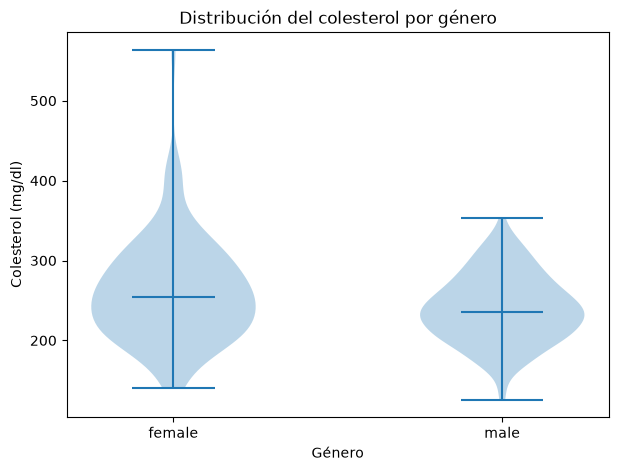

In [5]:
grupos = sorted(df["gender"].dropna().unique())
valores = [df.loc[df["gender"] == g, "cholesterol"].dropna() for g in grupos]

fig, ax = plt.subplots(figsize=(7, 5))
ax.violinplot(valores, showmedians=True)
ax.set_xticks(range(1, len(grupos) + 1), grupos)
ax.set_xlabel("Género")
ax.set_ylabel("Colesterol (mg/dl)")
ax.set_title("Distribución del colesterol por género")
plt.show()

## 2. Box Plot: edad por tipo de dolor torácico

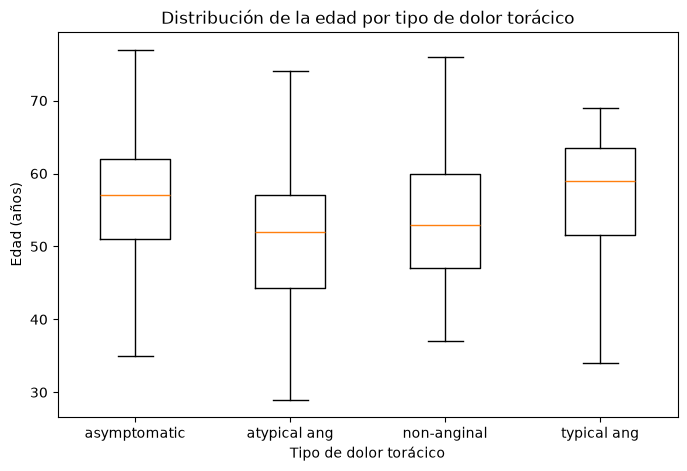

,count,mean,std,min,25%,50%,75%,max
chest pain,,,,,,,,
asymptomatic,144.0,55.72,8.29,35.0,51.00,57.0,62.0,77.0
atypical ang,50.0,51.36,9.51,29.0,44.25,52.0,57.0,74.0
non-anginal,86.0,53.70,9.32,37.0,47.00,53.0,60.0,76.0
typical ang,23.0,55.87,10.03,34.0,51.50,59.0,63.5,69.0


In [6]:
grupos = sorted(df["chest pain"].dropna().unique())
valores = [df.loc[df["chest pain"] == g, "age"].dropna() for g in grupos]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(valores, tick_labels=grupos)
ax.set_xlabel("Tipo de dolor torácico")
ax.set_ylabel("Edad (años)")
ax.set_title("Distribución de la edad por tipo de dolor torácico")
plt.show()

df.groupby("chest pain", observed=True)["age"].describe().round(2)

## 3. Distributions: presión arterial sistólica en reposo

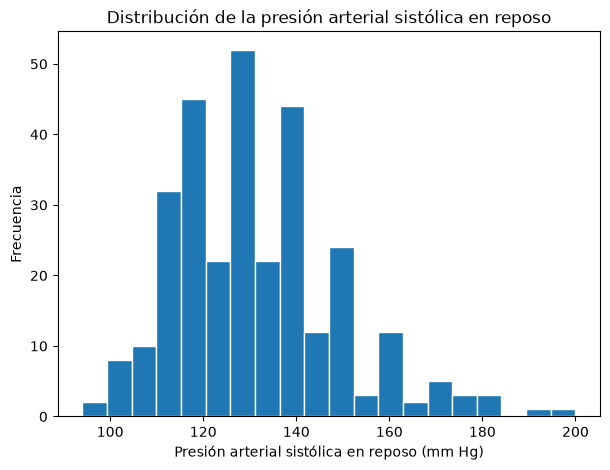

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(df["rest SBP"].dropna(), bins=20, edgecolor="white")
ax.set_xlabel("Presión arterial sistólica en reposo (mm Hg)")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución de la presión arterial sistólica en reposo")
plt.show()